In [5]:
import sys
import os
# Добавляем папку src, чтобы Питон видел наши файлы
sys.path.append(os.path.abspath("../src"))

import matplotlib.pyplot as plt
import numpy as np
from inr4d.data.acdc import load_acdc_patient
from inr4d.data.dataset import CoordinateDataset

print("Успешно импортировано!")

Успешно импортировано!


In [6]:
# Важно: здесь укажи путь к ЛЮБОМУ пациенту из твоей папки с датасетом на компе
# Например, если данные лежат в корне проекта:
data_path = "../data/acdc/patient049" 

volume = load_acdc_patient(data_path)
data = volume.data

print(f"Размерность данных [X, Y, Z, Время]: {data.shape}")
print(f"Физический размер вокселя (в мм): {volume.spacing}")
print(f"Минимальная яркость: {data.min()}, Максимальная: {data.max()}")

Размерность данных [X, Y, Z, Время]: (256, 216, 7, 35)
Физический размер вокселя (в мм): (np.float32(1.3671875), np.float32(1.3671875), np.float32(10.0))
Минимальная яркость: 0.0, Максимальная: 1514.0


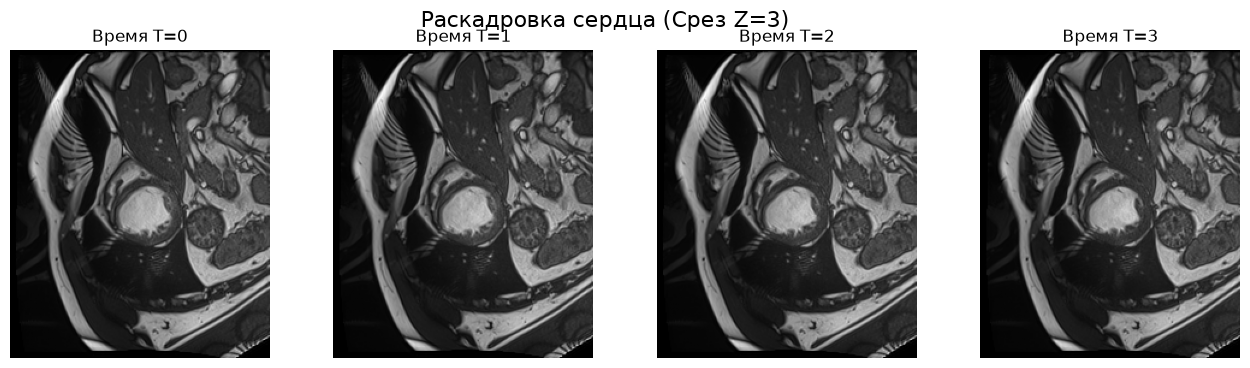

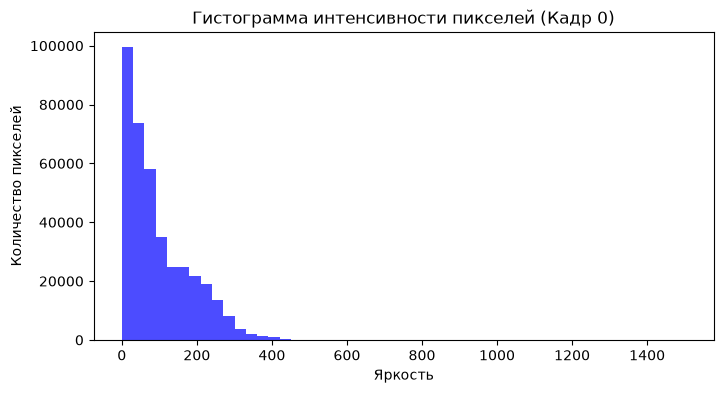

In [7]:
# AI-assisted: Slice viewer and frame-by-frame montage
time_frame = 0  # Смотрим на первый момент времени
z_slice = data.shape[2] // 2  # Берем срез ровно посередине по оси Z

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle(f'Раскадровка сердца (Срез Z={z_slice})', fontsize=16)

# Рисуем первые 4 кадра во времени
for t in range(4):
    if t < data.shape[3]:
        axes[t].imshow(data[:, :, z_slice, t], cmap='gray')
        axes[t].set_title(f'Время T={t}')
        axes[t].axis('off')
        
plt.show()

# Рисуем гистограмму яркости
plt.figure(figsize=(8, 4))
plt.hist(data[..., 0].flatten(), bins=50, color='blue', alpha=0.7)
plt.title("Гистограмма интенсивности пикселей (Кадр 0)")
plt.xlabel("Яркость")
plt.ylabel("Количество пикселей")
plt.show()